> ⚠️ **Saved outputs below are from the original run**, which trained at about 81×52 px by mistake (`docs/failures.md` F1.2). The code is fixed; re-running gives true 1/8 resolution.

# Phase 0: Setup & "Hello Splat" (Google Colab)

**Goal:** check that the whole toolchain works end to end before we work on quality.

What this notebook does:
1. Checks the GPU and mounts Google Drive (results are kept there between sessions)
2. Installs **gsplat** plus the example trainer's dependencies, and records exact versions
3. Runs a tiny rasterization smoke test
4. Downloads **only** the Mip-NeRF 360 *garden* scene at 1/8 and 1/4 resolution (≈ a few hundred MB, not the full 12 GB zip)
5. Trains a quick **7k-step** 3DGS model at 1/8 resolution
6. Reads the metrics (PSNR / SSIM / LPIPS) and exports a `.ply` you can open in [SuperSplat](https://superspl.at/editor)

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

**Exit criteria** (from README Phase 0):
- [ ] Training runs without crashing
- [ ] The `.ply` opens in SuperSplat and is recognisably the scene
- [ ] Versions are recorded (copy them into the README)

## 1. GPU check & Google Drive

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
import torch
assert torch.cuda.is_available(), "No GPU: Runtime → Change runtime type → T4 GPU"
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "|", torch.cuda.get_device_name(0))

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
torch 2.11.0+cu130 | CUDA 13.0 | Tesla T4


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/3dgs-digital-twin'   # persistent: results, exports, build cache
WORK    = '/content/work'                              # fast local disk: code + datasets (re-created each session)
for d in [f'{PROJECT}/results', f'{PROJECT}/exports', f'{PROJECT}/env', f'{PROJECT}/cache/torch_extensions', WORK]:
    os.makedirs(d, exist_ok=True)

# Cache gsplat's compiled CUDA kernels on Drive so later sessions don't recompile
os.environ['TORCH_EXTENSIONS_DIR'] = f'{PROJECT}/cache/torch_extensions'
print('Project dir:', PROJECT)

Mounted at /content/drive
Project dir: /content/drive/MyDrive/3dgs-digital-twin


## 2. Install gsplat

Tries a **prebuilt wheel** matching Colab's torch/CUDA first (fast). Falls back to the PyPI package, which **JIT-compiles** the CUDA kernels the first time they're used (~5–10 min once; the cache on Drive makes later sessions faster).

In [3]:
import torch, subprocess, sys
tv = torch.__version__.split('+')[0].split('.')
cu = (torch.version.cuda or '').replace('.', '')
wheel_index = f"https://docs.gsplat.studio/whl/pt{tv[0]}{tv[1]}cu{cu}"
print('Trying prebuilt wheel index:', wheel_index)
r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gsplat', '--index-url', wheel_index,
                    '--extra-index-url', 'https://pypi.org/simple'], capture_output=True, text=True)
if r.returncode != 0:
    print('No prebuilt wheel for this torch/CUDA combo → installing from PyPI (JIT compile on first use)')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gsplat'], check=True)
import importlib, gsplat; importlib.reload(gsplat)
print('gsplat', gsplat.__version__)

Trying prebuilt wheel index: https://docs.gsplat.studio/whl/pt211cu130
gsplat 1.5.3


In [4]:
# Clone the gsplat repo at the SAME version as the installed package (for examples/simple_trainer.py)
import gsplat, os
GSPLAT_VER = gsplat.__version__.split('+')[0]
REPO = f'{WORK}/gsplat'
if not os.path.exists(REPO):
    rc = os.system(f'git clone -q --depth 1 --branch v{GSPLAT_VER} https://github.com/nerfstudio-project/gsplat.git {REPO}')
    if rc != 0:
        print(f'Tag v{GSPLAT_VER} not found, cloning main instead (check for API drift)')
        os.system(f'git clone -q --depth 1 https://github.com/nerfstudio-project/gsplat.git {REPO}')
!cd {REPO} && git log -1 --format='%h %d %s'

937e299  (grafted, HEAD, tag: v1.5.3) Exclude cu118 and cu121 for windows build (#756)


In [9]:
# Install ninja for parallel builds
!pip install -q ninja

# Extract and install fused dependencies directly
import os
requirements_path = f'{REPO}/examples/requirements.txt'
with open(requirements_path, 'r') as f:
    reqs = f.read()

# Extract git urls and install them properly
import re
git_urls = re.findall(r'git\+https://github\.com/[^@\s]+@[0-9a-f]{40}', reqs)
for url in git_urls:
    print(f'Installing: {url}')
    os.system(f'pip install --no-build-isolation "{url}"')

# Clean and install remaining requirements
cleaned_reqs = []
for line in reqs.splitlines():
    if not any(k in line.lower() for k in ['git+https', 'numpy<2']):
        cleaned_reqs.append(line)

with open('/tmp/reqs.txt', 'w') as f:
    f.write('\n'.join(cleaned_reqs))

!pip install -q -r /tmp/reqs.txt
!pip install -q remotezip plyfile "numpy>=2.1,<2.5"

# Hotfix pycolmap np.uint64(-1) issue which crashes with OverflowError in NumPy 2.x
try:
    import pycolmap
except OverflowError:
    import site
    site_packages = site.getsitepackages()[0]
    target_file = os.path.join(site_packages, 'pycolmap', 'scene_manager.py')
    if os.path.exists(target_file):
        with open(target_file, 'r') as f:
            content = f.read()
        # Replace np.uint64(-1) with np.uint64(18446744073709551615)
        content = content.replace('np.uint64(-1)', 'np.uint64(18446744073709551615)')
        with open(target_file, 'w') as f:
            f.write(content)
        print("Successfully patched pycolmap's scene_manager.py for NumPy 2.x compatibility!")

# Confirm everything is available
import numpy, fused_ssim, pycolmap, tyro
print('numpy', numpy.__version__, '| trainer deps OK')

Installing: git+https://github.com/rmbrualla/pycolmap@cc7ea4b7301720ac29287dbe450952511b32125e
Installing: git+https://github.com/nerfstudio-project/nerfview@4538024fe0d15fd1a0e4d760f3695fc44ca72787
Installing: git+https://github.com/rahul-goel/fused-ssim@328dc9836f513d00c4b5bc38fe30478b4435cbb5
Installing: git+https://github.com/harry7557558/fused-bilagrid@90f9788e57d3545e3a033c1038bb9986549632fe
Successfully patched pycolmap's scene_manager.py for NumPy 2.x compatibility!
numpy 2.4.6 | trainer deps OK


## 3. Record versions (copy these into the README → §7)

In [10]:
import subprocess, torch, gsplat, platform, datetime
smi = subprocess.run(['nvidia-smi', '--query-gpu=name,driver_version', '--format=csv,noheader'],
                     capture_output=True, text=True).stdout.strip()
pkgs = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout
keep = [l for l in pkgs.splitlines() if any(k in l.lower() for k in
        ['torch', 'gsplat', 'fused', 'pycolmap', 'tyro', 'viser', 'nerfview', 'numpy', 'opencv', 'imageio'])]
report = '\n'.join([
    f'date: {datetime.date.today()}',
    f'python: {platform.python_version()}',
    f'gpu/driver: {smi}',
    f'torch: {torch.__version__} (CUDA {torch.version.cuda})',
    f'gsplat: {gsplat.__version__}',
    '', *keep])
print(report)
open(f'{PROJECT}/env/versions_phase0.txt', 'w').write(report)

date: 2026-11-03
python: 3.13.16
gpu/driver: Tesla T4, 580.82.07
torch: 2.11.0+cu130 (CUDA 13.0)
gsplat: 1.5.3

defusedxml==0.7.1
fused_bilagrid @ git+https://github.com/harry7557558/fused-bilagrid@90f9788e57d3545e3a033c1038bb9986549632fe
fused_ssim @ git+https://github.com/rahul-goel/fused-ssim@328dc9836f513d00c4b5bc38fe30478b4435cbb5
gsplat==1.5.3
ImageIO==2.38.1
imageio-ffmpeg==0.7.0
nerfview @ git+https://github.com/nerfstudio-project/nerfview@4538024fe0d15fd1a0e4d760f3695fc44ca72787
numpy==2.4.6
opencv-contrib-python==4.14.0.94
opencv-python==4.11.0.86
opencv-python-headless==5.0.0.93
pycolmap @ git+https://github.com/rmbrualla/pycolmap@cc7ea4b7301720ac29287dbe450952511b32125e
torch==2.11.0+cu130
torch_fidelity==0.4.0
torchao==0.10.0
torchaudio==2.11.0+cu130
torchcodec==0.11.0+cu130
torchdata==0.11.0
torchmetrics==1.9.0
torchsummary==1.5.1
torchtune==0.6.1
torchvision==0.26.0+cu130
tyro==1.0.16
viser==1.1.1


925

## 4. Smoke test: render random Gaussians (triggers JIT compile if needed)

OK: rendered (1, 256, 256, 3) in 792.3s (first call includes compilation)


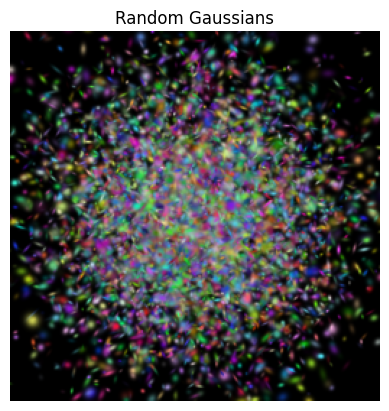

In [11]:
import torch, time
from gsplat import rasterization
dev = 'cuda'; N = 10_000
means = torch.randn(N, 3, device=dev) * 0.5 + torch.tensor([0, 0, 3.0], device=dev)
quats = torch.nn.functional.normalize(torch.randn(N, 4, device=dev), dim=-1)
scales = torch.rand(N, 3, device=dev) * 0.02
opacities = torch.rand(N, device=dev)
colors = torch.rand(N, 3, device=dev)
viewmats = torch.eye(4, device=dev)[None]
Ks = torch.tensor([[[300., 0, 128], [0, 300., 128], [0, 0, 1]]], device=dev)
t = time.time()
img, alpha, meta = rasterization(means, quats, scales, opacities, colors, viewmats, Ks, 256, 256)
torch.cuda.synchronize()
print(f'OK: rendered {tuple(img.shape)} in {time.time()-t:.1f}s (first call includes compilation)')
import matplotlib.pyplot as plt
plt.imshow(img[0].clamp(0, 1).cpu()); plt.axis('off'); plt.title('Random Gaussians'); plt.show()

## 5. Download only the *garden* scene

The official `360_v2.zip` is ~12 GB. `remotezip` uses HTTP range requests to pull **only** the files we need:
`sparse/` (COLMAP model), `poses_bounds.npy`, `images_8/` and `images_4/`.

gsplat's COLMAP loader needs an `images/` folder, so we symlink `images → images_8` and train with **`--data_factor 1`**. Don't use `--data_factor 8` here: with JPGs, gsplat downscales `images/` by that factor **again** (`docs/failures.md` F1.2).

In [12]:
from remotezip import RemoteZip
import os, time
URL = 'http://storage.googleapis.com/gresearch/refraw360/360_v2.zip'
SCENE = 'garden'
DATA = f'{WORK}/data/360_v2'
WANT = ('sparse/', 'poses_bounds.npy', 'images_8/', 'images_4/')

t = time.time()
with RemoteZip(URL) as z:
    members = [m for m in z.namelist()
               if f'{SCENE}/' in m and not m.endswith('/')
               and any(m.split(f'{SCENE}/', 1)[1].startswith(w) for w in WANT)]
    print(f'Downloading {len(members)} files for "{SCENE}"...')
    for m in members:
        rel = m.split(f'{SCENE}/', 1)[1]
        dst = f'{DATA}/{SCENE}/{rel}'
        if os.path.exists(dst):
            continue
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        with z.open(m) as src, open(dst, 'wb') as f:
            f.write(src.read())
print(f'Done in {time.time()-t:.0f}s')

SCENE_DIR = f'{DATA}/{SCENE}'
if not os.path.exists(f'{SCENE_DIR}/images'):
    os.symlink(f'{SCENE_DIR}/images_8', f'{SCENE_DIR}/images')
!du -sh {SCENE_DIR}/* && ls {SCENE_DIR}/images_8 | wc -l

Done in 19s
0	/content/work/data/360_v2/garden/images
187M	/content/work/data/360_v2/garden/images_4
49M	/content/work/data/360_v2/garden/images_8
28K	/content/work/data/360_v2/garden/poses_bounds.npy
59M	/content/work/data/360_v2/garden/sparse
185


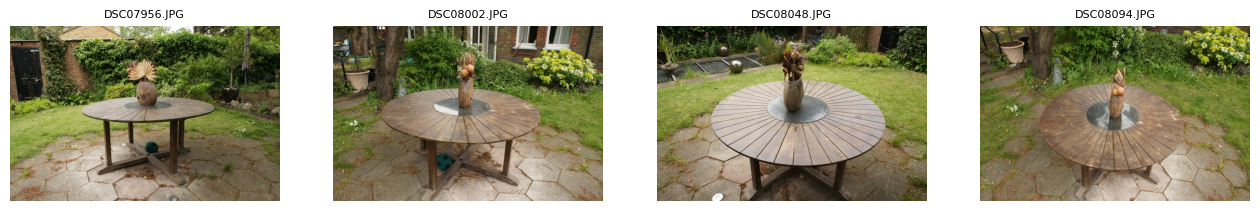

185 images, size (420, 648, 3)


In [13]:
# Look at a few input views
import glob, imageio.v2 as imageio, matplotlib.pyplot as plt
files = sorted(glob.glob(f'{SCENE_DIR}/images_8/*'))
fig, ax = plt.subplots(1, 4, figsize=(16, 3))
for a, f in zip(ax, files[::max(1, len(files)//4)]):
    a.imshow(imageio.imread(f)); a.set_title(os.path.basename(f), fontsize=8); a.axis('off')
plt.show()
print(len(files), 'images, size', imageio.imread(files[0]).shape)

## 6. Train: "hello splat" (7k steps, 1/8 resolution)

Expected on a T4: roughly 5–10 min (plus one-time compilation). Every 8th image is held out for evaluation (`test_every=8`, the standard Mip-NeRF 360 split).
Results go straight to Drive.

In [15]:

!touch {REPO}/examples/datasets/__init__.py
!cd {REPO}/examples && python -c "import datasets.colmap; print('local datasets OK')"

local datasets OK


In [16]:
RUN = 'phase0_garden_f8_7k'
RESULT_DIR = f'{PROJECT}/results/{RUN}'
!cd {REPO}/examples && python simple_trainer.py default \
    --data_dir {SCENE_DIR} --data_factor 1 \
    --result_dir {RESULT_DIR} \
    --max_steps 7000 --disable_viewer 2>&1 | grep -v -E '^\s*$' | tail -n 40

Step 6700: 3034 GSs duplicated, 581 GSs split. Now having 478183 GSs.
Step 6700: 967 GSs pruned. Now having 477216 GSs.
Step 6800: 3065 GSs duplicated, 614 GSs split. Now having 480895 GSs.
Step 6800: 921 GSs pruned. Now having 479974 GSs.
Step 6900: 3321 GSs duplicated, 712 GSs split. Now having 484007 GSs.
Step 6900: 874 GSs pruned. Now having 483133 GSs.
Step:  6999 {'mem': 0.7289009094238281, 'ellipse_time': 298.9700696468353, 'num_GS': 483133}
Running evaluation...
PSNR: 30.513, SSIM: 0.9484, LPIPS: 0.019 Time: 0.022s/image Number of GS: 483133
Running trajectory rendering...
Rendering trajectory: 100%|██████████| 174/174 [00:03<00:00, 52.22it/s]
loss=0.017| sh degree=3| : 100%|██████████| 7000/7000 [05:05<00:00, 22.91it/s]
Video saved to /content/drive/MyDrive/3dgs-digital-twin/results/phase0_garden_f8_7k/videos/traj_6999.mp4


## 7. Metrics & renders

In [17]:
import json, glob
stats = sorted(glob.glob(f'{RESULT_DIR}/stats/val_step*.json'))
assert stats, f'No eval stats found in {RESULT_DIR}/stats. Check the training log above.'
m = json.load(open(stats[-1]))
print(os.path.basename(stats[-1]))
for k, v in m.items():
    print(f'  {k:>12}: {v:.4f}' if isinstance(v, float) else f'  {k:>12}: {v}')

val_step6999.json
          psnr: 30.5134
          ssim: 0.9484
         lpips: 0.0187
  ellipse_time: 0.0219
        num_GS: 483133


24 eval renders


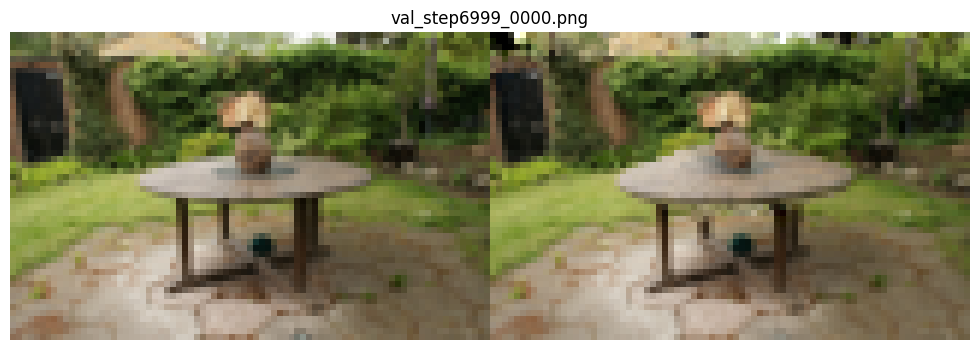

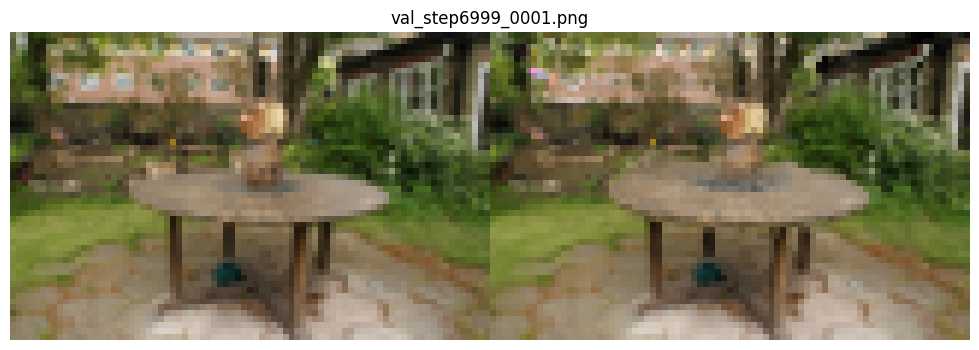

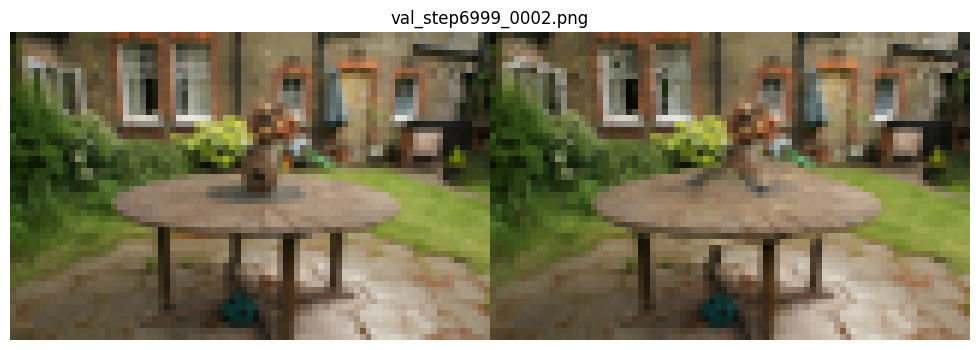

In [18]:
# Side-by-side GT | render images written by the trainer during eval
renders = sorted(glob.glob(f'{RESULT_DIR}/renders/val_step*_*.png'))
print(len(renders), 'eval renders')
for f in renders[:3]:
    plt.figure(figsize=(14, 4)); plt.imshow(imageio.imread(f)); plt.axis('off'); plt.title(os.path.basename(f)); plt.show()

## 8. Export `.ply` for SuperSplat

This converts the checkpoint to the **standard 3DGS PLY layout** (`x y z, f_dc_*, f_rest_*, opacity, scale_*, rot_*`), which SuperSplat, splatviz and Blender add-ons all read. It doesn't depend on any trainer flag.

In [19]:
import numpy as np, torch
from plyfile import PlyData, PlyElement

def ckpt_to_ply(ckpt_path, ply_path):
    s = torch.load(ckpt_path, map_location='cpu', weights_only=False)['splats']
    means = s['means'].numpy()
    sh0 = s['sh0'].transpose(1, 2).flatten(1).numpy()            # [N,1,3] -> [N,3]
    shN = s['shN'].transpose(1, 2).flatten(1).numpy()            # [N,K,3] -> [N,3K] (channel-major, 3DGS convention)
    opac = s['opacities'].numpy()[:, None]                       # logit space
    scales = s['scales'].numpy()                                 # log space
    quats = s['quats'].numpy()                                   # wxyz
    normals = np.zeros_like(means)
    attrs = ['x','y','z','nx','ny','nz'] + [f'f_dc_{i}' for i in range(sh0.shape[1])] \
          + [f'f_rest_{i}' for i in range(shN.shape[1])] + ['opacity'] \
          + [f'scale_{i}' for i in range(3)] + [f'rot_{i}' for i in range(4)]
    data = np.concatenate([means, normals, sh0, shN, opac, scales, quats], axis=1).astype(np.float32)
    el = np.empty(data.shape[0], dtype=[(a, 'f4') for a in attrs])
    el[:] = list(map(tuple, data))
    PlyData([PlyElement.describe(el, 'vertex')]).write(ply_path)
    return data.shape[0]

ckpts = sorted(glob.glob(f'{RESULT_DIR}/ckpts/*.pt'))
assert ckpts, 'No checkpoint found'
PLY = f'{PROJECT}/exports/{RUN}.ply'
n = ckpt_to_ply(ckpts[-1], PLY)
print(f'{n:,} Gaussians → {PLY} ({os.path.getsize(PLY)/1e6:.1f} MB)')

483,133 Gaussians → /content/drive/MyDrive/3dgs-digital-twin/exports/phase0_garden_f8_7k.ply (119.8 MB)


In [20]:
# Download to your PC, then drag-and-drop into https://superspl.at/editor
from google.colab import files
files.download(PLY)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Log the run

Appends one row to `results/metrics.csv` on Drive, using the table format from README §10.

In [21]:
import csv, datetime
row = {
    'date': str(datetime.date.today()), 'run': RUN, 'scene': SCENE, 'res': '1/8', 'strategy': 'default',
    'steps': 7000, 'num_gaussians': n,
    'psnr': round(m.get('psnr', float('nan')), 3), 'ssim': round(m.get('ssim', float('nan')), 4),
    'lpips': round(m.get('lpips', float('nan')), 4),
    'gpu': torch.cuda.get_device_name(0),
    'mem_gb': m.get('mem', ''),   # trainer-reported GPU memory, if present in its stats
    'ply_mb': round(os.path.getsize(PLY) / 1e6, 1),
}
CSV = f'{PROJECT}/results/metrics.csv'
new = not os.path.exists(CSV)
with open(CSV, 'a', newline='') as f:
    w = csv.DictWriter(f, fieldnames=row.keys())
    if new: w.writeheader()
    w.writerow(row)
print(open(CSV).read())

date,run,scene,res,strategy,steps,num_gaussians,psnr,ssim,lpips,gpu,mem_gb,ply_mb
2026-11-03,phase0_garden_f8_7k,garden,1/8,default,7000,483133,30.513,0.9484,0.0187,Tesla T4,,119.8



## ✅ Phase 0 checklist
- [ ] Training finished; metrics printed above
- [ ] `.ply` opens in SuperSplat and is recognisably the garden
- [ ] Copy `env/versions_phase0.txt` into README §7
- [ ] Note anything that broke in `docs/failures.md`

**Rough expectations:** a 7k-step run at 1/8 res should already look like the garden. PSNR in the mid-20s is normal here. Final quality is Phase 2's job.

**Next → Phase 1:** run COLMAP ourselves on garden and compare with the official poses.